# Tugas 2 - Klasifikasi Spam dengan Multinomial Naive Bayes

In [1]:
# Langkah 1 - Load dan Preprocessing Data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

df = pd.read_csv('data/spam.csv', encoding='latin-1')
df = df[['v1', 'v2']].rename(columns={'v1': 'Labels', 'v2': 'SMS'})
display(df.head())
print('Ukuran data:', df.shape)
print('Jumlah nilai kosong:')
print(df.isna().sum())
print('Jumlah duplikat:', df.duplicated().sum())
df = df.dropna().drop_duplicates().reset_index(drop=True)
print('Ukuran setelah dibersihkan:', df.shape)
print(df['Labels'].value_counts())

new_labels = {'ham': 0, 'spam': 1}
df['Labels'] = df['Labels'].map(new_labels)

Ukuran data: (5572, 2)
Jumlah nilai kosong:
Labels    0
SMS       0
dtype: int64
Jumlah duplikat: 403
Ukuran setelah dibersihkan: (5169, 2)
Labels
ham     4516
spam     653
Name: count, dtype: int64


,Labels,SMS
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [2]:
# Langkah 2 - Pisahkan Data Latih dan Data Uji
from sklearn.model_selection import train_test_split

X = df['SMS'].to_numpy(dtype=str)
y = df['Labels'].to_numpy(dtype=int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=50, stratify=y
)
print('Jumlah data latih:', len(X_train))
print('Jumlah data uji:', len(X_test))

Jumlah data latih: 4135
Jumlah data uji: 1034


In [3]:
# Langkah 3 - CountVectorizer dengan Stop Words
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

bow = CountVectorizer(stop_words='english')
X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

mnb_bow = MultinomialNB(alpha=1.0)
mnb_bow.fit(X_train_bow, y_train)
y_pred_bow = mnb_bow.predict(X_test_bow)
print('Jumlah fitur CountVectorizer:', len(bow.get_feature_names_out()))

Jumlah fitur CountVectorizer: 7359


In [4]:
# Langkah 4 - TF-IDF dengan Stop Words
tfidf = TfidfVectorizer(stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

mnb_tfidf = MultinomialNB(alpha=1.0)
mnb_tfidf.fit(X_train_tfidf, y_train)
y_pred_tfidf = mnb_tfidf.predict(X_test_tfidf)
print('Jumlah fitur TF-IDF:', len(tfidf.get_feature_names_out()))

Jumlah fitur TF-IDF: 7359


In [5]:
# Langkah 5 - Evaluasi dan Perbandingan Hasil
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

hasil = []
for nama, prediksi in [('CountVectorizer', y_pred_bow), ('TF-IDF', y_pred_tfidf)]:
    print(f'=== {nama} ===')
    print(classification_report(y_test, prediksi, target_names=['ham', 'spam'],
                                digits=4, zero_division=0))
    hasil.append({
        'Fitur': nama,
        'Akurasi': accuracy_score(y_test, prediksi),
        'Precision Spam': precision_score(y_test, prediksi, zero_division=0),
        'Recall Spam': recall_score(y_test, prediksi, zero_division=0),
        'F1 Spam': f1_score(y_test, prediksi, zero_division=0)
    })

tabel_hasil = pd.DataFrame(hasil)
display(tabel_hasil)

=== CountVectorizer ===
              precision    recall  f1-score   support

         ham     0.9835    0.9900    0.9868       903
        spam     0.9280    0.8855    0.9062       131

    accuracy                         0.9768      1034
   macro avg     0.9557    0.9378    0.9465      1034
weighted avg     0.9765    0.9768    0.9766      1034

=== TF-IDF ===
              precision    recall  f1-score   support

         ham     0.9606    1.0000    0.9799       903
        spam     1.0000    0.7176    0.8356       131

    accuracy                         0.9642      1034
   macro avg     0.9803    0.8588    0.9077      1034
weighted avg     0.9656    0.9642    0.9616      1034



,Fitur,Akurasi,Precision Spam,Recall Spam,F1 Spam
0,CountVectorizer,0.976789,0.928,0.885496,0.906250
1,TF-IDF,0.964217,1.000,0.717557,0.835556


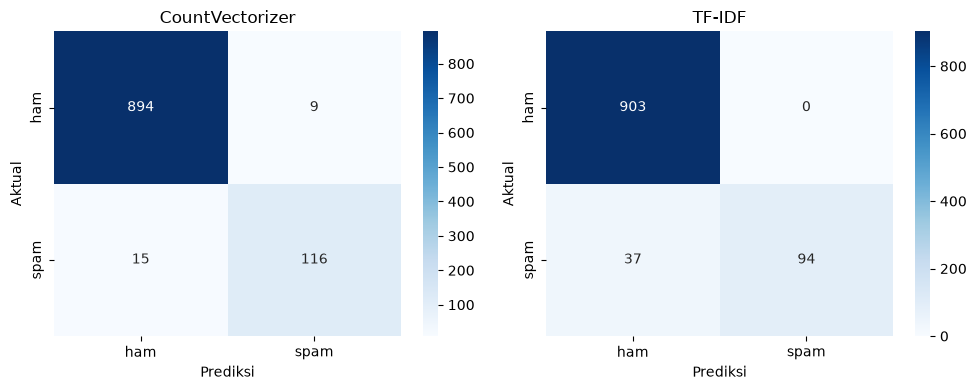

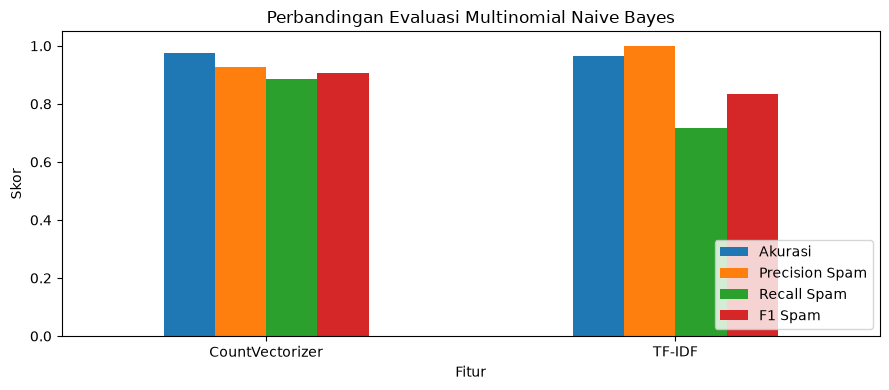

In [6]:
# Langkah 6 - Visualisasi Perbandingan
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, nama, prediksi in zip(axes, ['CountVectorizer', 'TF-IDF'],
                             [y_pred_bow, y_pred_tfidf]):
    cm = confusion_matrix(y_test, prediksi, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
    ax.set_title(nama)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
plt.tight_layout()
plt.show()

tabel_hasil.set_index('Fitur').plot(kind='bar', figsize=(9, 4), rot=0)
plt.title('Perbandingan Evaluasi Multinomial Naive Bayes')
plt.ylabel('Skor')
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()